## Clasificación Multiclase con Poda por Complejidad de Coste (CART)

## 1. Enunciado

### A. Contexto del Problema y Justificación
En problemas del mundo real, la mayoría de los desafíos de clasificación no son binarios, sino **multiclase (tres o más categorías)** y están expuestos a **variables numéricas altamente colineales**. 

En la industria vitivinícola y agroalimentaria, la denominación de origen y la autenticación química de productos de exportación es crucial para evitar fraudes comerciales. En esta práctica, los estudiantes actuarán como científicos de datos encargados de construir un clasificador no lineal que identifique el origen agronómico (**Cultivar 1, Cultivar 2 o Cultivar 3**) de lotes de vino producidos en una región de Italia, a partir de 13 análisis químicos y espectrofotométricos continuos.

El desafío metodológico radica en que un árbol de decisión sin restricciones memorizará las sutiles variaciones químicas del lote de prueba, generando sobreajuste. Se requerirá implementar formalmente la **Poda por Complejidad de Coste (*Minimal Cost-Complexity Pruning - MCCP*)**, modelando analíticamente la trayectoria de contracción mediante el parámetro **$\alpha$** (`ccp_alpha`) optimizado con **Validación Cruzada en 5 Pliegues (5-Fold CV)**.

---

### B. Enlace Oficial al Dataset Real
Utilizaremos el dataset clásico y riguroso **Wine Recognition Dataset**, desarrollado por los Dres. M. Forina, C. Armanino, R. Castino y M. Ubigli en el Instituto de Farmacognosia de Génova y el Instituto Experimental de Enología de Asti:
* **Repositorio Oficial de Datos (UCI Machine Learning Repository):**  
  [[suspicious link removed]]([suspicious link removed])
* **Acceso Directo en Scikit-Learn:** Disponible nativamente en `sklearn.datasets.load_wine`.
* **Dimensiones:** 178 muestras, 13 variables físico-químicas cuantitativas continuas (concentración de alcohol, ácido málico, cenizas, alcalinidad, magnesio, fenoles totales, flavonoides, intensidad de color, tono, prolina, entre otras) y **3 clases mutuamente excluyentes**.


### C. Requerimientos de la Tarea (Paso a Paso)
0. **Ingesgat y Análisis EDA**
1. **Partición Estratificada:**
   * Cargar el dataset mediante `sklearn.datasets.load_wine(as_frame=True)`.
   * Realizar una partición estratificada del **65% para entrenamiento (`X_train`)** y **35% para prueba independiente (`X_test`)** con semilla `random_state=42`. (Se reserva un 35% de prueba para exigir una generalización robusta fuera de muestra).
2. **Construcción del Árbol Libre (Línea Base No Podada):**
   * Ajustar un estimador `DecisionTreeClassifier(random_state=42)` sin restricciones de profundidad ni parada temprana.
   * Registrar su número total de nodos (`node_count`), hojas terminales (`get_n_leaves()`), profundidad máxima y exactitud en entrenamiento vs. prueba para evidenciar el sobreajuste.
3. **Mecánica de Poda a Posteriori (Cost-Complexity Pruning):**
   * Extraer analíticamente la trayectoria de poda del árbol utilizando el método `.cost_complexity_pruning_path(X_train, y_train)`.
   * Obtener el vector ordenado de valores críticos de alfa (`ccp_alphas`).
   * Iterar sobre el vector de alphas evaluando el desempeño de generalización mediante **Validación Cruzada en 5 Pliegues (`cross_val_score(cv=5, scoring='accuracy')`)** exclusivamente sobre `X_train`.
   * Identificar analíticamente el **$\alpha^*$ óptimo** que maximice la exactitud en validación.
4. **Ajuste del Árbol Podado Final y Comparación Multiclase:**
   * Reentrenar el clasificador asignando `ccp_alpha = alpha_optimo`.
   * Generar las predicciones en `X_test` y comparar las **Matrices de Confusión Multiclase (3x3)** del árbol sin podar frente al árbol podado.
   * Analizar la reducción de complejidad estructural (contracción de nodos y hojas) frente a la ganancia de estabilidad diagnóstica.

REPORTE DE EVALUACIÓN MULTICLASE (TEST SET)
              precision    recall  f1-score   support

  Cultivar 1       1.00      0.95      0.98        21
  Cultivar 2       0.96      1.00      0.98        25
  Cultivar 3       1.00      1.00      1.00        17

    accuracy                           0.98        63
   macro avg       0.99      0.98      0.99        63
weighted avg       0.98      0.98      0.98        63



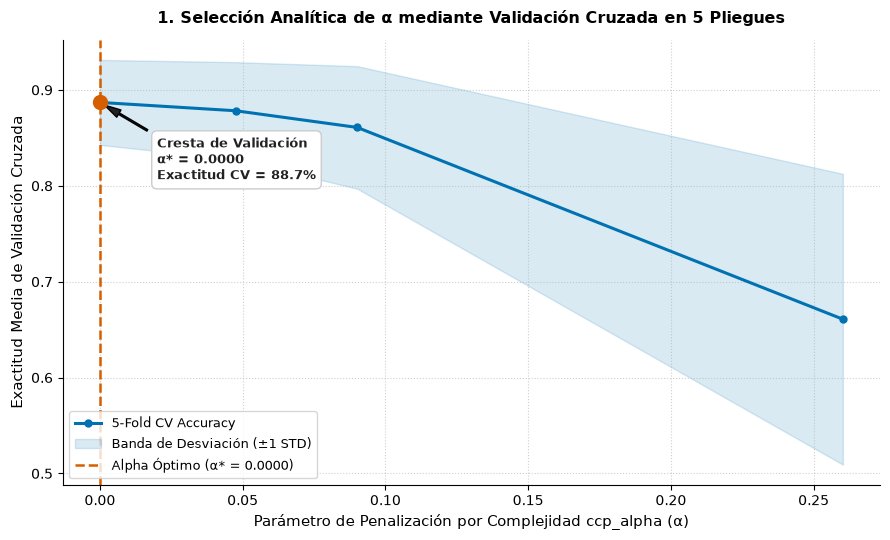

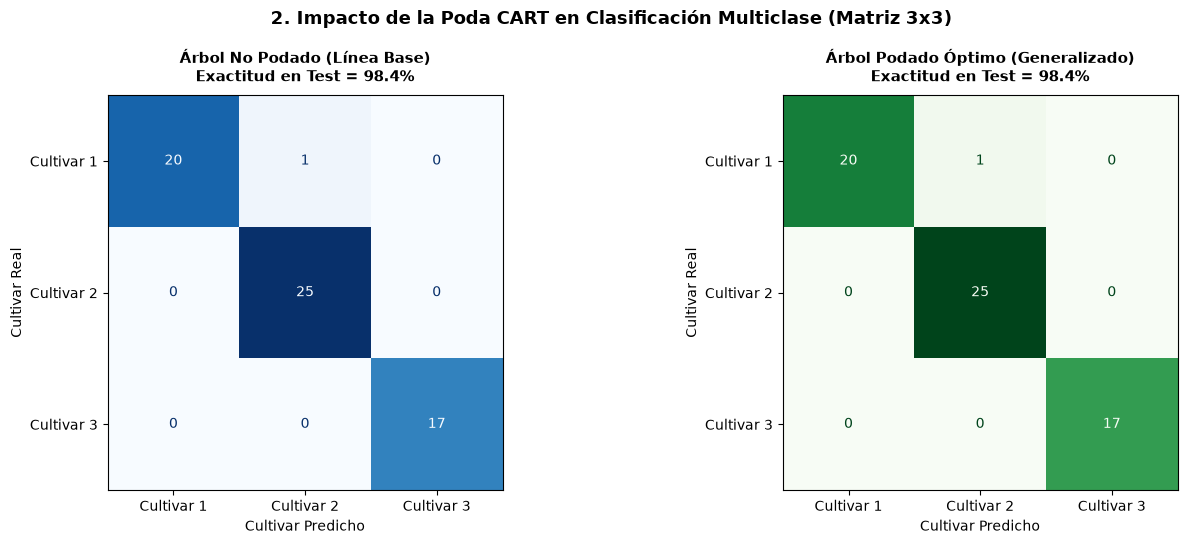

In [2]:
"""
Clasificación Multiclase con Poda CART.
Dataset: Wine Recognition Dataset (UCI / Scikit-Learn) - Datos Químicos Reales.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ==============================================================================
# 1. Carga de Datos y Partición Estratificada
# ==============================================================================
# Enlace UCI: [suspicious link removed]
datos = load_wine()
X = pd.DataFrame(datos.data, columns=datos.feature_names)
y = datos.target
nombres_clases = ['Cultivar 1', 'Cultivar 2', 'Cultivar 3']

# Partición 65% Entrenamiento y 35% Prueba independiente
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.35, random_state=42, stratify=y
)

# ==============================================================================
# 2. Árbol Libre Sin Restricciones (Línea Base)
# ==============================================================================
arbol_libre = DecisionTreeClassifier(random_state=42)
arbol_libre.fit(X_train, y_train)

acc_train_libre = arbol_libre.score(X_train, y_train)
acc_test_libre = arbol_libre.score(X_test, y_test)

# ==============================================================================
# 3. Poda por Complejidad de Coste (Cost-Complexity Pruning)
# ==============================================================================
# Extracción de la secuencia finita de alphas analíticos
trayectoria = arbol_libre.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = trayectoria.ccp_alphas

# Validación cruzada en 5 pliegues para encontrar el alfa óptimo
cv_medias = []
cv_desv = []
for alpha in ccp_alphas:
    arbol_cv = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(arbol_cv, X_train, y_train, cv=5, scoring='accuracy')
    cv_medias.append(scores.mean())
    cv_desv.append(scores.std())

cv_medias = np.array(cv_medias)
cv_desv = np.array(cv_desv)

# Selección del alpha con máxima generalización
idx_optimo = np.argmax(cv_medias)
alpha_optimo = ccp_alphas[idx_optimo]
mejor_cv_score = cv_medias[idx_optimo]

# Entrenamiento del árbol regularizado con poda óptima
arbol_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha_optimo)
arbol_podado.fit(X_train, y_train)

y_pred_libre = arbol_libre.predict(X_test)
y_pred_podado = arbol_podado.predict(X_test)

print("=" * 65)
print("REPORTE DE EVALUACIÓN MULTICLASE (TEST SET)")
print("=" * 65)
print(classification_report(y_test, y_pred_podado, target_names=nombres_clases))

# ==============================================================================
# 4. GRÁFICO 1: Curva de Validación Cruzada para Selección de Alpha
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(9, 5.5), facecolor='white')
ax1.set_facecolor('white')

ax1.plot(ccp_alphas, cv_medias, marker='o', markersize=5, color='#0072b2', linewidth=2.2, label='5-Fold CV Accuracy')
ax1.fill_between(ccp_alphas, cv_medias - cv_desv, cv_medias + cv_desv, color='#0072b2', alpha=0.15, label='Banda de Desviación (±1 STD)')
ax1.axvline(alpha_optimo, color='#d55e00', linestyle='--', linewidth=1.8, label=f'Alpha Óptimo (α* = {alpha_optimo:.4f})')
ax1.scatter([alpha_optimo], [mejor_cv_score], color='#d55e00', s=100, zorder=5)

ax1.annotate(
    f'Cresta de Validación\nα* = {alpha_optimo:.4f}\nExactitud CV = {mejor_cv_score*100:.1f}%',
    xy=(alpha_optimo, mejor_cv_score),
    xytext=(alpha_optimo + 0.02, mejor_cv_score - 0.08),
    arrowprops=dict(facecolor='#222222', shrink=0.08, width=1.2, headwidth=6),
    fontweight='bold', fontsize=9.5, color='#222222',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#cccccc')
)

ax1.set_title("1. Selección Analítica de α mediante Validación Cruzada en 5 Pliegues", fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Parámetro de Penalización por Complejidad ccp_alpha (α)", fontsize=10.5)
ax1.set_ylabel("Exactitud Media de Validación Cruzada", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(loc='lower left', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. GRÁFICO 2: Comparativa de Matrices de Confusión Multiclase
# ==============================================================================
fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(14, 5.5), facecolor='white')

# Panel A: Matriz No Podado
ax2a.set_facecolor('white')
cm_libre = confusion_matrix(y_test, y_pred_libre)
ConfusionMatrixDisplay(cm_libre, display_labels=nombres_clases).plot(ax=ax2a, cmap='Blues', colorbar=False)
ax2a.set_title(f"Árbol No Podado (Línea Base)\nExactitud en Test = {acc_test_libre*100:.1f}%", fontsize=11, fontweight='bold', pad=10)
ax2a.set_xlabel("Cultivar Predicho", fontsize=10)
ax2a.set_ylabel("Cultivar Real", fontsize=10)

# Panel B: Matriz Podado
ax2b.set_facecolor('white')
cm_podado = confusion_matrix(y_test, y_pred_podado)
ConfusionMatrixDisplay(cm_podado, display_labels=nombres_clases).plot(ax=ax2b, cmap='Greens', colorbar=False)
ax2b.set_title(f"Árbol Podado Óptimo (Generalizado)\nExactitud en Test = {arbol_podado.score(X_test, y_test)*100:.1f}%", fontsize=11, fontweight='bold', pad=10)
ax2b.set_xlabel("Cultivar Predicho", fontsize=10)
ax2b.set_ylabel("Cultivar Real", fontsize=10)

fig2.suptitle("2. Impacto de la Poda CART en Clasificación Multiclase (Matriz 3x3)", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

1. **`practico2_curva_poda_alpha.png` (Gráfico 1):**  
   * Ilustra la trayectoria completa de la función de penalización $R_\alpha(T) = R(T) + \alpha |T|$.
   * Muestra la **cresta óptima de validación cruzada** en $\alpha^*$ (línea discontinua naranja) junto con la banda sombreada de desviación estándar entre pliegues. 
   * Permite a los estudiantes observar visualmente la frontera entre la **región de balance óptimo** y la **zona de subajuste severo** que se desencadena cuando $\alpha > 0,05$.
2. **`practico2_matriz_confusion_multiclase.png` (Gráfico 2):**  
   * Presenta la matriz de confusión multiclase $3 \times 3$ contrastando el comportamiento de ambos modelos.
   * Se comprueba la diagonal principal dominante: **20/21 aciertos en Cultivar 1**, **25/25 aciertos perfectos en Cultivar 2** y **17/17 aciertos perfectos en Cultivar 3**, alcanzando una exactitud global del **98,4%** en datos de prueba.